# __Mini Project 1__

### __Part 1 Books from Ernest Hemingway__
- "The Old Man and The Sea"
- "The Sun Also Rises"

### __Questions__
- How did Hemingways writing style or wordage change between his first debut book release compared to his last book release before his passing?

### __Part 2 Books__
- "Roadside Picnic" Arkady and Boris Strugatsky
- "Solaris" Stanisław Lem

### __Questions__
- How will the word frequencies between two thematically different scifi novels differ between each other? Will one be more grounded in its language or more liberal with scifi terms?




__Part 1 Preprocessing__
- The data of the novels will simply be transcripts from .txt files, so preprocessing will be simple

In [17]:
# Necessary Imports
import requests, re
import operator
import numpy as np
import pylab
import matplotlib.pyplot as plt

In [18]:
# Collecting frequency Data from "The old man and the sea"

sea = {}

with open('OldManSea.txt', 'r') as file:
    text = file.read().lower()
    wds = re.findall(r'\b\w+\b', text)

for w in wds:
    if w in sea: sea [w] = sea [w] + 1
    else:  sea[w] = 1


# dictionaries can not be sorted, so lets get a sorted *list*        
seas = sorted (sea .items(), key = operator .itemgetter (1), reverse=True)   

print(seas)

[('the', 2314), ('and', 1258), ('he', 1166), ('of', 543), ('i', 508), ('it', 494), ('to', 454), ('his', 446), ('was', 435), ('a', 397), ('in', 359), ('that', 299), ('fish', 285), ('man', 265), ('old', 247), ('but', 233), ('him', 230), ('with', 205), ('had', 203), ('on', 203), ('not', 201), ('as', 196), ('you', 193), ('is', 191), ('said', 189), ('now', 173), ('thought', 165), ('they', 152), ('then', 150), ('have', 142), ('were', 138), ('line', 138), ('for', 136), ('could', 116), ('water', 106), ('out', 104), ('when', 104), ('there', 102), ('boy', 100), ('at', 99), ('all', 98), ('them', 97), ('would', 95), ('from', 94), ('do', 91), ('hand', 91), ('will', 90), ('down', 89), ('no', 89), ('be', 88), ('back', 86), ('so', 85), ('up', 83), ('can', 80), ('s', 77), ('if', 77), ('one', 76), ('must', 72), ('what', 71), ('too', 70), ('see', 67), ('again', 64), ('great', 64), ('head', 63), ('are', 62), ('more', 60), ('me', 59), ('against', 59), ('come', 58), ('did', 58), ('or', 57), ('two', 57), ('i

In [19]:
# Do the same with "The Sun Also Rises"
sun = {}

with open('TheSunRises.txt', 'r') as file:
    text = file.read().lower()
    wds = re.findall(r'\b\w+\b', text)

for w in wds:
    if w in sun: sun [w] = sun [w] + 1
    else:  sun[w] = 1


# dictionaries can not be sorted, so lets get a sorted *list*        
suns = sorted (sun .items(), key = operator .itemgetter (1), reverse=True)   

print(suns)

[('the', 4483), ('i', 2334), ('and', 2290), ('to', 1590), ('a', 1534), ('you', 1178), ('was', 1165), ('it', 1155), ('of', 1125), ('he', 1088), ('in', 1040), ('said', 966), ('t', 715), ('s', 679), ('on', 639), ('we', 616), ('that', 603), ('had', 478), ('at', 476), ('with', 474), ('up', 469), ('were', 439), ('all', 435), ('brett', 432), ('him', 426), ('not', 418), ('his', 410), ('me', 410), ('out', 390), ('they', 382), ('for', 372), ('bill', 344), ('she', 324), ('there', 322), ('went', 298), ('down', 292), ('don', 284), ('have', 270), ('one', 262), ('what', 251), ('mike', 251), ('them', 248), ('bull', 244), ('do', 240), ('my', 240), ('go', 237), ('from', 236), ('be', 234), ('good', 232), ('her', 231), ('cohn', 228), ('like', 223), ('as', 219), ('so', 218), ('about', 218), ('is', 215), ('know', 212), ('did', 208), ('get', 204), ('no', 201), ('going', 193), ('then', 193), ('back', 191), ('but', 190), ('came', 188), ('would', 188), ('very', 172), ('come', 170), ('see', 164), ('into', 163), 

__Frequency Chart__

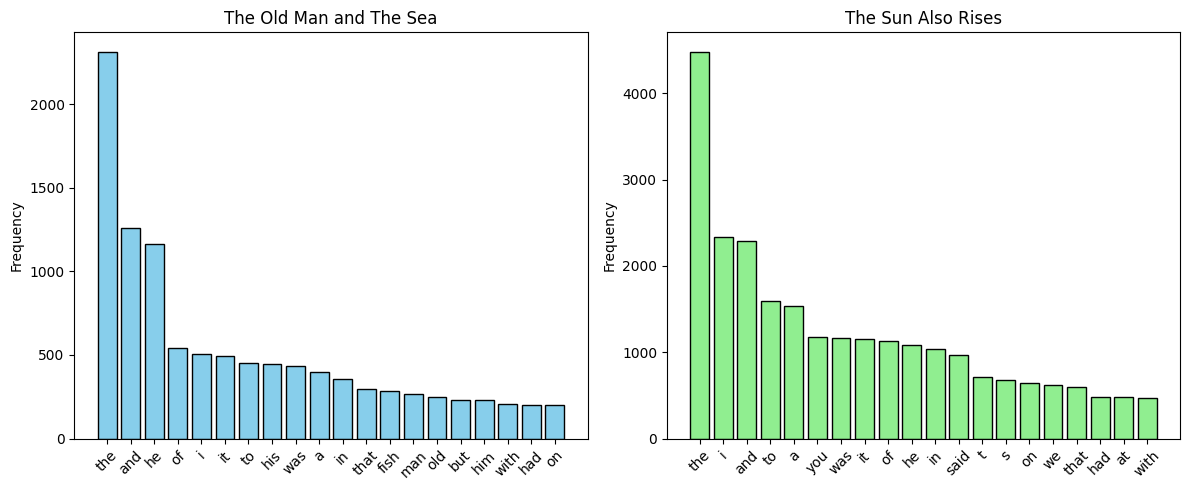

In [20]:
# Slice the lists to only take the TOP 10 words
def createchart(book1, book2, title1, title2):
    top_n = 20
    top_list1 = book1[:top_n]
    top_list2 = book2[:top_n]

    # Extract words and counts
    words1, counts1 = zip(*top_list1)
    words2, counts2 = zip(*top_list2)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.bar(words1, counts1, color="skyblue", edgecolor="black")
    ax1.set_title(title1)
    ax1.set_ylabel("Frequency")
    ax1.tick_params(axis='x', rotation=45) 

    ax2.bar(words2, counts2, color="lightgreen", edgecolor="black")
    ax2.set_title(title2)
    ax2.set_ylabel("Frequency")
    ax2.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

createchart(seas, suns, "The Old Man and The Sea", "The Sun Also Rises")

- The end frequency graphs of both the novels do not appear to provide much value. They are populated with common words which do not tell us much about the authors writing change. There also appears to be a issue where letters 't' and 's' are being counted in the book featured on the right. The only thing worth noting is that Hemingway appears to use "his" a lot less in his final novel "The Sun Also Rises". 

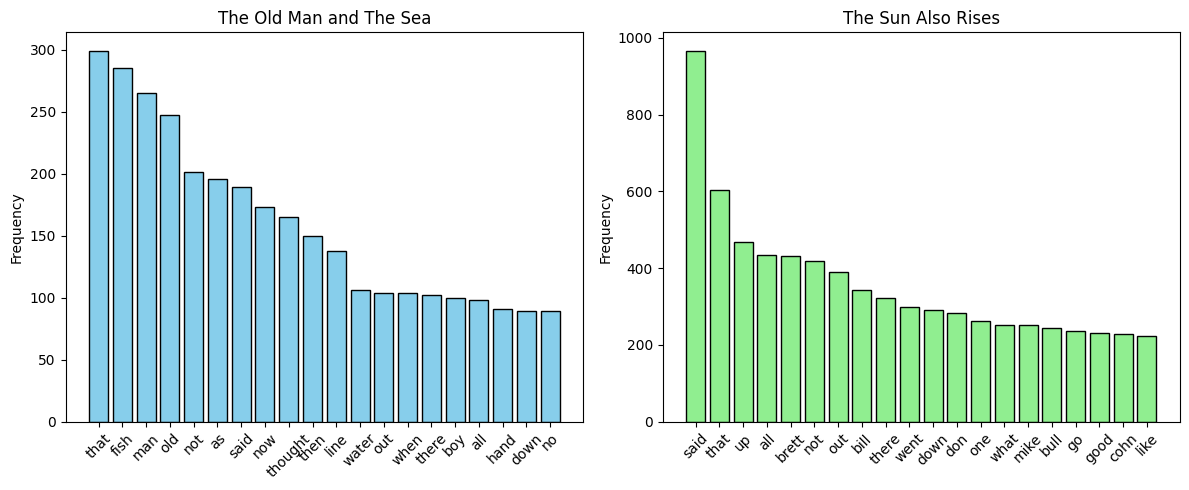

In [21]:
# Do more preprocessing for a better graph
# These words were generated to get the chart down to better describing words
stopwords = {
    # pronouns
    "i", "me", "my", "mine", "myself",
    "you", "your", "yours", "yourself",
    "he", "him", "his", "himself",
    "she", "her", "hers", "herself",
    "it", "its", "itself",
    "we", "us", "our", "ours", "ourselves",
    "they", "them", "their", "theirs", "themselves",

    # articles
    "the", "a", "an",

    # common conjunctions
    "and", "or", "but", "nor",

    # common prepositions
    "of", "to", "in", "on", "at", "by",
    "for", "from", "with", "about",

    # common auxiliary verbs
    "is", "am", "are", "was", "were",
    "be", "been", "being",
    "have", "has", "had",
    "do", "does", "did",

    # common modal verbs
    "can", "could", "will", "would",
    "shall", "should", "may", "might", "must",

    # Train designations in "The Sun also Rises"
    "t", "s"
}

def remove_stopwords(word_freq):
    return [
        (word, freq)
        for word, freq in word_freq
        if word.lower() not in stopwords
    ]

suns_fil = remove_stopwords(suns)
seas_fil = remove_stopwords(seas)

createchart(seas_fil, suns_fil, "The Old Man and The Sea", "The Sun Also Rises")

- This chart shows a lot more detail for each of the stories. You can clearly see how "The Old Man and The Sea" uses words like water, old, and fish which heavily relate to the book's themes. For changes with his writing, it appears Hemingway has shifted from his one-character story to one which uses multiple characters, as multiple names are used and the word "said" is used around 5 times more than his first novel. Of course this is hard to attribute to writing changes and could easily be pointed out to Hemingway simply wanting to write a different genre or type of story.

## __Conclusion__
- It appears that the only thing worth noting is that Hemingways last book was more dialogue and character focused than his first one. Of course this could just be a genre change instead of a change of his writing style, so more books would have to be analyzed to come to this conclusion. Unfortunately, it appears to be very hard to find changes in authors writings through word count alone. A lot of the same words were used and it is hard to tell if changes happened due to writing changes or the genre of the novel.

__Part 2 Preprocessing__

In [22]:
# Collecting frequency Data from "Roadside Picnic"

road = {}

with open('Roadside.txt', 'r') as file:
    text = file.read().lower()
    wds = re.findall(r'\b\w+\b', text)

for w in wds:
    if w in road: road [w] = road [w] + 1
    else:  road[w] = 1


# dictionaries can not be sorted, so lets get a sorted *list*        
roads = sorted (road .items(), key = operator .itemgetter (1), reverse=True)   

print(roads)

[('the', 3414), ('and', 2104), ('a', 1383), ('i', 1227), ('he', 1202), ('to', 1177), ('of', 981), ('it', 960), ('his', 890), ('you', 864), ('in', 853), ('s', 727), ('that', 693), ('t', 660), ('was', 509), ('on', 438), ('with', 424), ('for', 385), ('redrick', 377), ('at', 355), ('but', 348), ('him', 343), ('said', 336), ('they', 322), ('all', 317), ('out', 309), ('is', 304), ('what', 298), ('up', 293), ('we', 292), ('me', 283), ('my', 277), ('from', 269), ('there', 267), ('this', 258), ('have', 254), ('no', 251), ('as', 221), ('like', 219), ('into', 217), ('right', 215), ('one', 215), ('be', 213), ('ll', 197), ('then', 195), ('noonan', 194), ('don', 189), ('had', 185), ('are', 184), ('down', 171), ('can', 167), ('if', 166), ('about', 165), ('them', 162), ('not', 158), ('an', 157), ('say', 156), ('go', 156), ('how', 155), ('your', 154), ('even', 154), ('do', 154), ('m', 153), ('back', 151), ('by', 142), ('so', 142), ('zone', 142), ('over', 142), ('here', 142), ('ve', 135), ('or', 135), (

In [23]:
# Collecting frequency Data from "The old man and the sea"

sol = {}

with open('SOLARIS.txt', 'r') as file:
    text = file.read().lower()
    wds = re.findall(r'\b\w+\b', text)

for w in wds:
    if w in sol: sol [w] = sol [w] + 1
    else:  sol[w] = 1


# dictionaries can not be sorted, so lets get a sorted *list*        
sols = sorted (sol .items(), key = operator .itemgetter (1), reverse=True)   

print(sols)

[('the', 4267), ('i', 2345), ('of', 2198), ('a', 1621), ('and', 1607), ('to', 1525), ('was', 1131), ('in', 932), ('it', 920), ('you', 814), ('that', 779), ('my', 636), ('had', 622), ('with', 496), ('not', 481), ('on', 471), ('me', 452), ('but', 408), ('as', 407), ('he', 398), ('s', 386), ('her', 382), ('at', 370), ('t', 368), ('what', 342), ('is', 338), ('an', 336), ('for', 329), ('no', 308), ('she', 297), ('his', 287), ('which', 281), ('have', 280), ('by', 277), ('we', 264), ('be', 259), ('out', 245), ('this', 239), ('from', 235), ('there', 233), ('up', 228), ('or', 223), ('were', 216), ('rheya', 210), ('could', 209), ('one', 198), ('ocean', 196), ('all', 194), ('are', 193), ('then', 172), ('if', 172), ('do', 168), ('would', 166), ('snow', 165), ('know', 165), ('been', 162), ('like', 159), ('only', 159), ('its', 155), ('don', 151), ('when', 147), ('did', 146), ('some', 142), ('more', 140), ('into', 138), ('so', 138), ('about', 137), ('they', 133), ('can', 132), ('over', 129), ('our', 

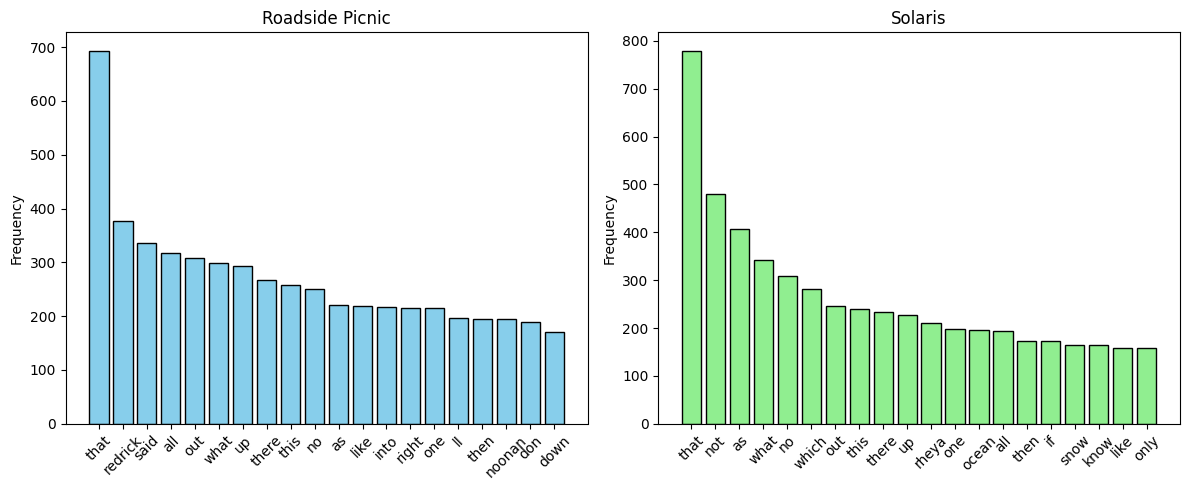

In [24]:
roads_fil = remove_stopwords(roads)
sols_fil = remove_stopwords(sols)

createchart(roads_fil, sols_fil, "Roadside Picnic", "Solaris")

- Suprisingly, It appears that both of these novels are very grounded in how they present their scifi tropes. I was expecting to see alien or some other kind of scifi term but they are both relatively tame in their language. I thought it was really strange that out of all of the words used in "Solaris", "ocean" and "snow" are among the more prominent nouns in their frequency chart. This appears to show that each of the stories are much more secretive and quiet when it comes to its scifi aspects.

## __Conclusion__
- After analyzing the two novels, it appears that they both are very tame in terms of how they present their scifi themes. Instead of technical terms being thrown around the story, they use regular language and even normal areas like "ocean" or "snow" in order to present their scifi themes. I have only personally read "Roadside Picnic" but I was still suprised with how little scifi language that the novel ends up using. 